# The learned surrogate against the engine at the reference point: encoding, onnxruntime and the error per output

**Question:** How closely does the released neural surrogate reproduce the engine at the reference case S01, which of its ten outputs is the worst, and what does the product answer when the model is not there?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of topic 01-getting-started
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- load a released model bundle through the pipeline's validating loader, and say what it checks;
- encode an operating point the way the network expects and run its ONNX graph with onnxruntime;
- decode the ten outputs and compare them with the engine's, output by output;
- see what the pipeline returns when a bundle is missing, and why that answer is labelled.

## Setup

This topic adds onnxruntime, which runs the released graphs, and jsonschema, which the loader uses to validate each model's contract against its schema.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.27.0 jsonschema==4.26.0
```

The imports are the model bundle functions of the pipeline, the feature encoding, the engine and the sweep ranges that define the surrogate's training domain. The cell prints the four versions.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib', 'onnxruntime', 'jsonschema'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.bundles import load_bundle, session_for, decode_outputs, engine_outputs, surrogate_predict, released_slots, SURROGATE_OUTPUTS
from pipeline.model.crusher import Operating, evaluate
from pipeline.model.crusher.encoding import encode_input
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.27.0
jsonschema 4.26.0


## Data

The reference case S01, and the released surrogate: its contract and its two graphs, a float32 one and an 8-bit quantised one. The surrogate and the autoencoder are released ChancaDEM models, trained by the product's own pipeline on a Latin-hypercube sweep of the engine and committed with their contracts (`surrogate-model`, `anomaly-model`). Licence class: MIT, as the rest of the repository; the training data is synthetic, drawn from the engine. Files read: `data/derived/manifests/S01.json`, `data/derived/models/surrogate.json`, `data/derived/models/surrogate.onnx` and `data/derived/models/surrogate.int8.onnx`.

The cell reads the operating point and fixes the models folder.

In [2]:
# Read the S01 operating point and fix the folder of the released models
op = Operating(**json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"])
models_dir = ROOT / "data" / "derived" / "models"
print(op.machine, op.css_mm, op.throw_mm, op.speed_rpm, op.feed_x63_mm, op.feed_m, op.ore_axb)

cone-sec 32.0 30.0 360.0 90.0 1.2 55.0


## Method

**Step 1, the bundle.** A model is released when its JSON contract validates against its schema, its standardiser vectors are consistent, and every graph it names exists with the byte size and the SHA-256 digest the contract records. `load_bundle` does all of it and raises an error that names the file when any check fails, so an altered graph can never be served silently. The cell loads the surrogate's bundle and prints what the contract says: the architecture, the inputs and outputs, and the size and digest of each graph.

In [3]:
# Load the validated surrogate bundle and print what its contract states
bundle = load_bundle("surrogate-model", models_dir)
print("released slots:", released_slots(models_dir))
print("architecture:", bundle["architecture"].split(";")[0])
print("inputs:", bundle["machine_order"], bundle["input_order"])
print("outputs:", bundle["output_order"])
for kind, graph in bundle["graphs"].items():
    print(f"{kind:8s} {graph['bytes']:6d} bytes  sha256 {graph['sha256'][:12]}...")

released slots: {'surrogate-model': True, 'anomaly-model': True}
architecture: 11-64-64-32-10 MLP, GELU
inputs: ['cone-sec', 'cone-tert', 'jaw', 'cone-short-head', 'gyratory'] ['css_mm', 'throw_mm', 'speed_rpm', 'feed_x63_mm', 'feed_m', 'ore_axb']
outputs: ['p80_mm', 'p50_mm', 'p20_mm', 'pass_1', 'pass_4', 'pass_8', 'pass_16', 'pass_32', 'throughput_tph', 'power_kw']
float32   32449 bytes  sha256 233024c3fb93...
int8      15880 bytes  sha256 34f70a8dca3b...


**Step 2, the encoding.** The network takes 11 numbers: a one-hot code of the machine type (five columns, in the contract's order) followed by the six continuous inputs, each standardised with the mean and the standard deviation that the training stored, $(x - \mu)/\sigma$. Getting this wrong is silent, since the network always returns something; the encoder is therefore a pipeline function shared by training, evaluation and the web port, and the notebook calls it and never writes its own. The cell encodes S01 and prints the vector next to the raw inputs.

In [4]:
# Encode S01 as the network expects it and print the 11 numbers
vector = encode_input(op, bundle["in_mean"], bundle["in_std"])
print("one-hot (cone-sec, cone-tert, jaw, cone-short-head, gyratory):", vector[:5])
for name, raw, z in zip(bundle["input_order"], (op.css_mm, op.throw_mm, op.speed_rpm, op.feed_x63_mm, op.feed_m, op.ore_axb), vector[5:]):
    print(f"{name:12s} raw {raw:7.2f}  standardised {z:+.3f}")

one-hot (cone-sec, cone-tert, jaw, cone-short-head, gyratory): [1.0, 0.0, 0.0, 0.0, 0.0]
css_mm       raw   32.00  standardised -0.479
throw_mm     raw   30.00  standardised +0.389
speed_rpm    raw  360.00  standardised +0.032
feed_x63_mm  raw   90.00  standardised -0.496
feed_m       raw    1.20  standardised -0.334
ore_axb      raw   55.00  standardised -0.683


**Step 3, one run.** The cell opens an onnxruntime session on the float32 graph, feeds the encoded vector under the input name the contract gives and decodes the ten standardised outputs back to engineering units: $y = z\,\sigma + \mu$, and a power of ten for the three size outputs, which were fitted in logarithmic space for positivity. It then asks the engine for the same ten numbers and prints both with the relative difference.

In [5]:
# Run the float32 graph on S01, decode its outputs and set them beside the engine's
session = session_for(models_dir, bundle["graphs"]["float32"])
z = session.run(None, {"x": np.array([vector], np.float32)})[0]
network = dict(zip(bundle["output_order"], decode_outputs(z, bundle)[0]))
teacher = engine_outputs(evaluate(op))
errors = {k: (network[k] - teacher[k]) / teacher[k] * 100 for k in SURROGATE_OUTPUTS}
for k in SURROGATE_OUTPUTS:
    print(f"{k:15s} network {network[k]:9.3f}  engine {teacher[k]:9.3f}  error {errors[k]:+6.2f} %")
print("mean absolute error:", round(float(np.mean(np.abs(list(errors.values())))), 2), "%")

p80_mm          network    27.505  engine    27.698  error  -0.70 %
p50_mm          network    11.795  engine    12.090  error  -2.44 %
p20_mm          network     1.789  engine     1.829  error  -2.21 %
pass_1          network     0.148  engine     0.150  error  -1.45 %
pass_4          network     0.277  engine     0.288  error  -3.92 %
pass_8          network     0.393  engine     0.403  error  -2.48 %
pass_16         network     0.612  engine     0.579  error  +5.66 %
pass_32         network     0.838  engine     0.869  error  -3.57 %
throughput_tph  network   655.002  engine   643.158  error  +1.84 %
power_kw        network   275.587  engine   287.399  error  -4.11 %
mean absolute error: 2.84 %


The figure draws the ten relative errors. A network is often judged by one number, its R squared; here the point is the spread of its errors across outputs.

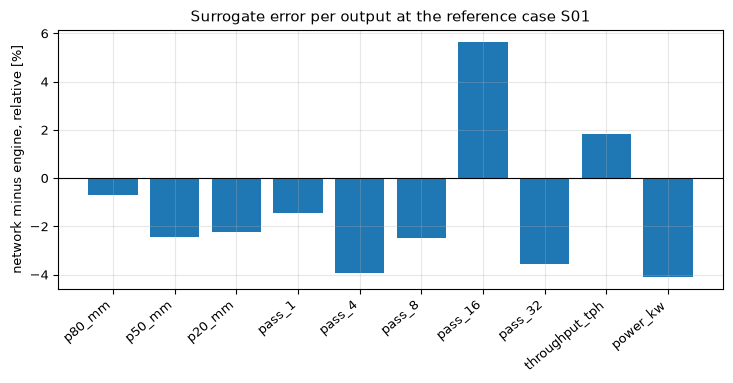

In [6]:
# Bar chart of the surrogate's relative error per output at S01
fig, ax = plt.subplots()
ax.bar(range(10), [errors[k] for k in SURROGATE_OUTPUTS])
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(10), SURROGATE_OUTPUTS, rotation=40, ha="right")
ax.set_ylabel("network minus engine, relative [%]")
ax.set_title("Surrogate error per output at the reference case S01")
fig.tight_layout()
plt.show()

The errors are small and mixed in sign: the largest is +5.66 percent on `pass_16`, the fraction of the product finer than 16 mm, and the smallest is -0.70 percent on P80, the quantity a plant cares most about. Nothing in the figure says that the errors at S01 represent the errors elsewhere: it is one point, chosen for its familiarity, and the held-out draw of notebook 02 is what measures the typical case. It does not show the sign structure either, which looks random here and is not guaranteed to be.

**Step 4, the response to a curve.** The setting is the lever a user moves most. The cell sweeps S01's closed-side setting from 8 to 60 mm and draws P80 from the network and from the engine, asking the pipeline's wrapper `surrogate_predict`, which loads the bundle, encodes, runs and decodes in one call and says which provenance answered.

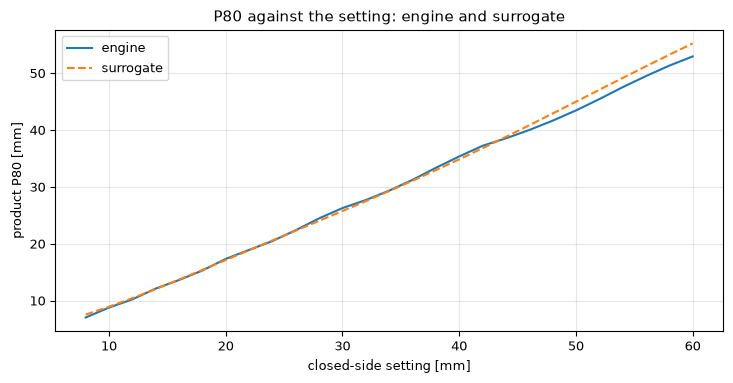

provenance of the answer: real | curve is non-decreasing: True


In [7]:
# Sweep the setting of S01 and draw P80 from the network (through the pipeline's wrapper) and from the engine
from dataclasses import replace

settings = np.linspace(8, 60, 27)
curve_network = [surrogate_predict(replace(op, css_mm=float(c)), models_dir)[0]["p80_mm"] for c in settings]
curve_engine = [evaluate(replace(op, css_mm=float(c))).p80 for c in settings]
fig, ax = plt.subplots()
ax.plot(settings, curve_engine, label="engine")
ax.plot(settings, curve_network, "--", label="surrogate")
ax.set_xlabel("closed-side setting [mm]")
ax.set_ylabel("product P80 [mm]")
ax.set_title("P80 against the setting: engine and surrogate")
ax.legend()
fig.tight_layout()
plt.show()
print("provenance of the answer:", surrogate_predict(op, models_dir)[1], "| curve is non-decreasing:", bool(np.all(np.diff(curve_network) > -1e-3)))

The two curves overlay to the eye and the network's is monotone, the physical property that the product tests on every machine. The deviation is largest at the wide end of the range, above a 45 mm setting, where the network runs above the engine by up to about 2 mm. What it does not show is the part of the space where there is no training data, which notebook 03 visits.

**Step 5, when the model is not there.** The product's rule for a missing or invalid bundle is that the engine answers, with the provenance labelled `baseline`, so a result is never presented as the network's when it is not. The cell points the wrapper at a folder with no model and prints what it returns for the same operating point, next to the answer with the real bundle.

In [8]:
# Ask for the same point with the real bundle and with a folder that holds no model
real_answer, real_provenance = surrogate_predict(op, models_dir)
missing_answer, missing_provenance = surrogate_predict(op, ROOT / "no-such-models-folder")
print("real bundle   :", real_provenance, round(real_answer["p80_mm"], 3), "mm P80")
print("missing bundle:", missing_provenance, round(missing_answer["p80_mm"], 3), "mm P80 (the engine's own value)")
print("released slots with the missing folder:", released_slots(ROOT / "no-such-models-folder"))

real bundle   : real 27.505 mm P80
missing bundle: baseline 27.698 mm P80 (the engine's own value)
released slots with the missing folder: {'surrogate-model': False, 'anomaly-model': False}


## Results

**Answer:** at S01 the surrogate reproduces the engine's ten outputs with a mean absolute error of 2.84 percent, from -0.70 percent on P80 to +5.66 percent on `pass_16`, and its P80 curve against the setting is monotone and overlays the engine's. When the bundle is missing the wrapper returns the engine's own value, 27.698 mm, with the provenance `baseline`, instead of the network's 27.505 mm labelled `real`, and the two released slots read as not released.

The figure of errors shows no output with a large error at this point; the sweep shows the network follows the engine's shape across the setting. A validator would conclude that the released network is a faithful emulator of the engine near the reference case, and that the product's refusal to pass an engine value off as the network's is implemented and checkable. This does not yet say how it behaves on the average held-out point, nor away from the training domain, nor against a real plant: notebook 02 and notebook 03 take those in turn.

## Summary

A released model is a contract, a graph and a digest; the loader validates all three and the wrapper labels what answered. The network emulates the engine at S01 to about 3 percent, worst on the share finer than 16 mm. Notebook 02 measures it on a held-out draw of 2196 operating points across all five machines, and asks the second released model, the autoencoder, what it detects.

## References

- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193